# 주차별 계절성으로 상승·하락을 맞힐 수 있을까

**AI 프로그래밍 및 실습 프로젝트 — 보조 실험**

"매년 이 주차에는 오른다" 같은 패턴이 있다면, 1년 52주 중 어느 주에 사고팔지 정할 수 있다.
이 노트북은 S&P 500, KOSPI, 금 ETF(GLD), 하이트진로로 이 생각을 세 단계로 검증한다.

1. **집계**: 20년 안팎의 데이터로 주차별 평균 수익률과 상승 비율을 계산한다.
2. **절반 검증**: 앞 절반 기간에 좋았던 주차가 뒤 절반에서도 좋았는지 본다.
3. **ML 예측**: 주차 통계를 특성으로 만들어 다음 해의 상승·하락을 예측한다.

결론부터 말하면, 1단계에서는 패턴이 보이지만 3단계에서는 사라진다.
과거 데이터에 맞는 패턴과 미래를 맞히는 패턴은 다르다는, 과대적합의 사례다.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

## 1. 데이터

변동성 예측 노트북이 저장해 둔 `data/prices.csv`(야후 파이낸스 일별 시세)를 쓴다.
금요일 종가 기준 주간 수익률(%)을 만들고, 각 주에 ISO 주차 번호(1~52)를 붙인다. 53주차는 52주차에 합친다.

하이트진로는 2009년 10월 이전 데이터가 거래량 0, 가격 고정이라 그 뒤부터만 쓴다.

In [2]:
ASSETS = {"SP500": "S&P 500", "KOSPI": "KOSPI", "GOLD": "Gold ETF (GLD)", "HITE": "Hite Jinro"}

prices = pd.read_csv("data/prices.csv", parse_dates=["date"])
dead = (prices["volume"] == 0) & (prices["high"] == prices["low"]) & prices["asset"].isin(["HITE", "KOSPI"])
prices = prices[~dead]


def weekly_returns(asset):
    d = prices[prices["asset"] == asset].set_index("date").sort_index()
    close = d["close"].resample("W-FRI").last()
    n_days = d["close"].resample("W-FRI").count()
    w = pd.DataFrame({"ret": close.pct_change() * 100, "n": n_days}).dropna()
    w = w[(w["n"] >= 3) & (w.index <= d.index.max())]   # 거래일 3일 미만인 주, 아직 안 끝난 주 제외
    iso = w.index.isocalendar()
    w["woy"] = iso.week.astype(int).clip(upper=52)
    w["year"] = iso.year.astype(int)
    w["up"] = (w["ret"] > 0).astype(int)
    return w


weekly = {a: weekly_returns(a) for a in ASSETS}
pd.DataFrame({
    a: {"시작": w.index[0].date(), "끝": w.index[-1].date(), "연수": w["year"].nunique(), "주 수": len(w),
        "주간 평균 수익률(%)": round(w["ret"].mean(), 2), "상승 비율": round(w["up"].mean(), 3)}
    for a, w in weekly.items()
}).T

,시작,끝,연수,주 수,주간 평균 수익률(%),상승 비율
SP500,2005-01-14,2026-11-20,22,1141,0.18,0.571
KOSPI,2005-01-14,2026-11-20,22,1118,0.18,0.563
GOLD,2005-01-14,2026-11-20,22,1141,0.21,0.559
HITE,2009-10-30,2026-11-20,18,870,0.0,0.48


## 2. 주차별 평균 수익률

주차마다 그 주차에 해당하는 모든 해의 수익률을 모아 평균, 중앙값, 상승 비율을 낸다.
평균이 0과 다른지는 t값으로 본다(|t| > 2면 대략 p < 0.05).

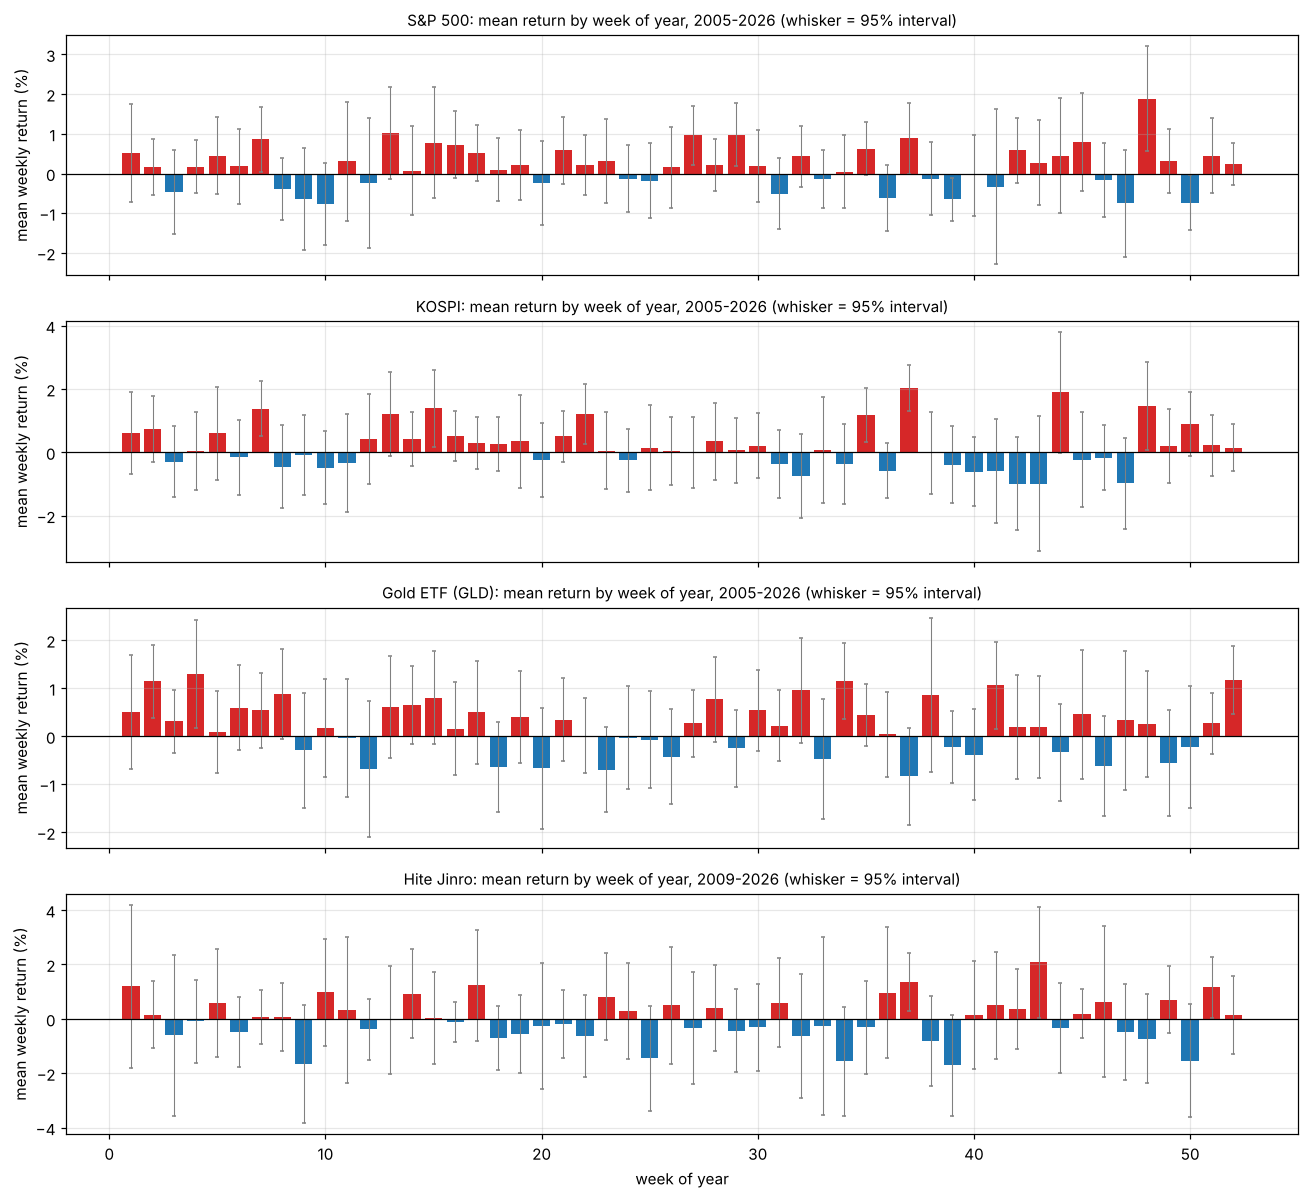

In [3]:
def by_week(w):
    g = w.groupby("woy")["ret"].agg(years="size", mean="mean", median="median", std="std", best="max", worst="min")
    g["up_rate"] = w.groupby("woy")["up"].mean()
    g["t"] = g["mean"] / (g["std"] / np.sqrt(g["years"]))
    return g


tables = {a: by_week(w) for a, w in weekly.items()}

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, a in zip(axes, ASSETS):
    g, w = tables[a], weekly[a]
    colors = ["tab:red" if v >= 0 else "tab:blue" for v in g["mean"]]
    ax.bar(g.index, g["mean"], color=colors, yerr=1.96 * g["std"] / np.sqrt(g["years"]),
           error_kw=dict(lw=0.7, ecolor="gray", capsize=1.5))
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("mean weekly return (%)")
    ax.set_title(f"{ASSETS[a]}: mean return by week of year, {w['year'].min()}-{w['year'].max()} (whisker = 95% interval)", fontsize=10)
axes[-1].set_xlabel("week of year")
plt.tight_layout()
plt.show()

In [4]:
rows = {}
for a, g in tables.items():
    top, bottom = g["mean"].nlargest(3), g["mean"].nsmallest(3)
    rows[a] = {
        "평균 수익률 상위 3주차": ", ".join(f"{k}주 {v:+.2f}%" for k, v in top.items()),
        "평균 수익률 하위 3주차": ", ".join(f"{k}주 {v:+.2f}%" for k, v in bottom.items()),
        "|t|>2 주차 수": int((g["t"].abs() > 2).sum()),
    }
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows).T

,평균 수익률 상위 3주차,평균 수익률 하위 3주차,|t|>2 주차 수
SP500,"48주 +1.88%, 13주 +1.02%, 29주 +0.98%","10주 -0.78%, 47주 -0.75%, 50주 -0.73%",6
KOSPI,"37주 +2.05%, 44주 +1.89%, 48주 +1.45%","42주 -1.00%, 43주 -0.98%, 47주 -0.98%",6
GOLD,"4주 +1.29%, 52주 +1.17%, 34주 +1.16%","37주 -0.84%, 23주 -0.69%, 12주 -0.68%",5
HITE,"43주 +2.08%, 37주 +1.35%, 17주 +1.23%","39주 -1.71%, 9주 -1.66%, 34주 -1.55%",3


눈에 띄는 주차가 있다. 하지만 **52개 주차를 한꺼번에 보면 아무 패턴이 없어도 2~3개(52 × 0.05 ≈ 2.6)는 우연히 유의하게 나온다.**
하이트진로는 딱 그 수준이고, 나머지 셋은 그보다 조금 많다. 이것이 진짜 패턴인지 다음 단계에서 확인한다.

그래프의 회색 선(95% 구간)이 대부분 0을 걸치는 것도 봐야 한다. 주차당 표본이 20개 안팎이라 평균의 오차가 크다.

## 3. 절반 검증

기간을 앞뒤 절반으로 나눈다. 진짜 계절 패턴이라면 **앞 절반에서 상승 비율이 높았던 주차가 뒤 절반에서도 높아야** 한다.

- 앞 절반에서 상승 비율 상위 10개 주차와 하위 10개 주차를 고른다.
- 그 주차들이 뒤 절반에서 실제로 오른 비율을 비교한다.

In [5]:
rows = {}
for a, w in weekly.items():
    years = sorted(w["year"].unique())
    half = years[len(years) // 2]
    first, second = w[w["year"] < half], w[w["year"] >= half]
    p1, p2 = first.groupby("woy")["up"].mean(), second.groupby("woy")["up"].mean()
    top, bottom = p1.nlargest(10).index, p1.nsmallest(10).index
    rows[a] = {
        "앞 절반": f"{years[0]}~{half - 1}", "뒤 절반": f"{half}~{years[-1]}",
        "앞뒤 주차별 상승 비율 상관": round(p1.corr(p2), 3),
        "상위 10주차의 뒤 절반 상승 비율": round(second[second["woy"].isin(top)]["up"].mean(), 3),
        "하위 10주차의 뒤 절반 상승 비율": round(second[second["woy"].isin(bottom)]["up"].mean(), 3),
        "뒤 절반 전체 상승 비율": round(second["up"].mean(), 3),
    }
half_check = pd.DataFrame(rows).T
half_check

,앞 절반,뒤 절반,앞뒤 주차별 상승 비율 상관,상위 10주차의 뒤 절반 상승 비율,하위 10주차의 뒤 절반 상승 비율,뒤 절반 전체 상승 비율
SP500,2005~2015,2016~2026,0.137,0.583,0.536,0.579
KOSPI,2005~2015,2016~2026,-0.034,0.565,0.565,0.538
GOLD,2005~2015,2016~2026,0.305,0.618,0.454,0.546
HITE,2009~2017,2018~2026,-0.132,0.442,0.488,0.475


상위 10주차와 하위 10주차의 뒤 절반 상승 비율이 비슷하면 패턴이 이어지지 않은 것이다.
차이가 나는 자산이 있더라도 주차당 표본이 10개 안팎이라 우연일 수 있다. 그래서 마지막으로 실제 예측을 해 본다.

## 4. ML로 다음 해 예측하기

주차 번호를 그대로 넣으면 모델이 52개 범주를 외워 버린다. 대신 **"지금까지 이 주차가 어땠는지"** 를 숫자 특성으로 만든다.
예측 대상 주가 속한 해보다 **이전 해의 데이터로만** 계산해 미래 정보가 새지 않게 한다.

| 묶음 | 특성 | 의미 |
|---|---|---|
| 계절 | `s_mean`, `s_up`, `s_t` | 과거 같은 주차의 평균 수익률, 상승 비율, t값 |
| | `s_mean3`, `s_up3` | 앞뒤 주차까지 포함한 3주의 평균 수익률, 상승 비율 |
| 최근 | `l1`, `l2`, `m4`, `m12`, `m52` | 직전 1·2주 수익률, 4·12·52주 누적 수익률 |
| | `v4`, `lvix`, `dvix` | 최근 4주 변동성, VIX 수준과 변화 |

타깃은 그 주가 상승(1)인지 하락(0)인지다.

In [6]:
vix = np.log(prices[prices["asset"] == "VIX"].set_index("date")["close"].resample("W-FRI").last())
F_SEASON = ["s_mean", "s_up", "s_t", "s_mean3", "s_up3"]
F_RECENT = ["l1", "l2", "m4", "m12", "m52", "v4", "lvix", "dvix"]


def add_features(w):
    w = w.copy()
    season = []
    for year, k in zip(w["year"], w["woy"]):
        past = w[w["year"] < year]                       # 이전 해만 사용
        same = past.loc[past["woy"] == k, "ret"]
        near = past.loc[past["woy"].isin([(k - 2) % 52 + 1, k, k % 52 + 1]), "ret"]
        t = same.mean() / (same.std() / np.sqrt(len(same))) if len(same) > 2 else np.nan
        season.append([same.mean(), (same > 0).mean(), t, near.mean(), (near > 0).mean(), len(same)])
    w[F_SEASON + ["s_n"]] = season
    prev = w["ret"].shift(1)                             # 직전 주까지의 정보
    w["l1"], w["l2"] = prev, w["ret"].shift(2)
    for k in (4, 12, 52):
        w[f"m{k}"] = prev.rolling(k).sum()
    w["v4"] = prev.rolling(4).std()
    w["lvix"] = vix.reindex(w.index).ffill().shift(1)
    w["dvix"] = w["lvix"].diff()
    return w[w["s_n"] >= 8].dropna()                     # 같은 주차 표본이 8개 이상 쌓인 뒤부터


data = {a: add_features(w) for a, w in weekly.items()}
data["KOSPI"][["ret", "woy", "year", "up"] + F_SEASON].tail(3).round(3)

,ret,woy,year,up,s_mean,s_up,s_t,s_mean3,s_up3
date,,,,,,,,,
2026-11-06,-11.710,45,2026,0,0.319,0.476,0.567,0.583,0.540
2026-11-13,4.562,46,2026,1,-0.397,0.524,-0.803,-0.242,0.508
2026-11-20,-7.949,47,2026,0,-0.648,0.524,-0.941,0.135,0.587


### 워크포워드 평가

시계열이므로 해마다 **그 전 해까지로 학습하고 그 해를 예측**한다. 이렇게 모은 예측 전체로 정확도를 낸다.

비교 대상
- **항상 다수 쪽**: 학습 기간에 상승이 더 많았으면 항상 상승이라고 답한다.
- **규칙**: 과거 같은 주차의 평균 수익률이 양수면 상승이라고 답한다.
- **모델 4종 × 특성 묶음 3종**: 로지스틱 회귀, k-최근접 이웃, 랜덤 포레스트, 그레이디언트 부스팅

In [7]:
def make_models():
    return {
        "로지스틱 회귀": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
        "k-최근접 이웃": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
        "랜덤 포레스트": RandomForestClassifier(n_estimators=300, min_samples_leaf=15, random_state=SEED),
        "그레이디언트 부스팅": HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=100, random_state=SEED),
    }


FEATURE_SETS = {"계절": F_SEASON, "계절+최근": F_SEASON + F_RECENT, "최근": F_RECENT}


def walk_forward(w):
    test_years = [y for y in sorted(w["year"].unique()) if y >= w["year"].min() + 3]
    pred = {}
    y_true, rets = [], []
    for year in test_years:
        train, test = w[w["year"] < year], w[w["year"] == year]
        y_true += list(test["up"])
        rets += list(test["ret"])
        pred.setdefault(("기준선", "항상 다수 쪽"), []).extend([int(train["up"].mean() >= 0.5)] * len(test))
        pred.setdefault(("기준선", "규칙: 같은 주차 평균 > 0"), []).extend((test["s_mean"] > 0).astype(int))
        for fs, cols in FEATURE_SETS.items():
            for name, model in make_models().items():
                pred.setdefault((fs, name), []).extend(model.fit(train[cols], train["up"]).predict(test[cols]))
    return test_years, np.array(y_true), np.array(rets), {k: np.array(v) for k, v in pred.items()}


results = {a: walk_forward(w) for a, w in data.items()}

acc = pd.DataFrame({a: {k: (p == y).mean() for k, p in pred.items()} for a, (_, y, _, pred) in results.items()})
acc.index = pd.MultiIndex.from_tuples(acc.index, names=["특성", "방법"])
info = pd.DataFrame({
    a: {"테스트 기간": f"{ty[0]}~{ty[-1]}", "주 수": len(y),
        "우연 범위(95%)": f"{0.5 - 1.96 * np.sqrt(0.25 / len(y)):.3f}~{0.5 + 1.96 * np.sqrt(0.25 / len(y)):.3f}"}
    for a, (ty, y, _, _) in results.items()
}).T
print(info.to_string())
acc.round(3)

          테스트 기간  주 수   우연 범위(95%)
SP500  2015~2026  621  0.461~0.539
KOSPI  2015~2026  606  0.460~0.540
GOLD   2015~2026  621  0.461~0.539
HITE   2019~2026  400  0.451~0.549


SP500  KOSPI   GOLD   HITE
특성    방법                                          
기준선   항상 다수 쪽           0.575  0.538  0.507  0.490
      규칙: 같은 주차 평균 > 0  0.530  0.493  0.525  0.490
계절    로지스틱 회귀           0.575  0.517  0.509  0.505
      k-최근접 이웃          0.573  0.523  0.514  0.530
      랜덤 포레스트           0.560  0.523  0.488  0.535
      그레이디언트 부스팅        0.557  0.533  0.515  0.502
계절+최근 로지스틱 회귀           0.549  0.493  0.499  0.520
      k-최근접 이웃          0.523  0.513  0.491  0.505
      랜덤 포레스트           0.559  0.512  0.514  0.528
      그레이디언트 부스팅        0.546  0.503  0.551  0.502
최근    로지스틱 회귀           0.551  0.505  0.510  0.520
      k-최근접 이웃          0.541  0.525  0.531  0.488
      랜덤 포레스트           0.560  0.503  0.504  0.500
      그레이디언트 부스팅        0.565  0.517  0.514  0.495

"우연 범위"는 동전 던지기로 그 주 수만큼 맞혔을 때 정확도가 95% 확률로 들어가는 구간이다.
정확도가 이 안에 있으면 찍은 것과 구분할 수 없다.

한 조합만 골라 보면 운 좋게 높은 것이 있을 수 있으니, 특성 묶음별로 **모델 4종의 평균**을 기준선과 비교한다.

In [8]:
summary = pd.concat([
    acc.loc[("기준선", "항상 다수 쪽")].rename("항상 다수 쪽"),
    acc.loc[("기준선", "규칙: 같은 주차 평균 > 0")].rename("규칙: 같은 주차 평균 > 0"),
    acc.loc["계절"].mean().rename("계절 특성 모델 4종 평균"),
    acc.loc["계절+최근"].mean().rename("계절+최근 특성 모델 4종 평균"),
    acc.loc["최근"].mean().rename("최근 특성 모델 4종 평균"),
], axis=1).T
summary.round(3)

,SP500,KOSPI,GOLD,HITE
항상 다수 쪽,0.575,0.538,0.507,0.490
규칙: 같은 주차 평균 > 0,0.530,0.493,0.525,0.490
계절 특성 모델 4종 평균,0.566,0.524,0.506,0.518
계절+최근 특성 모델 4종 평균,0.544,0.505,0.514,0.514
최근 특성 모델 4종 평균,0.554,0.512,0.515,0.501


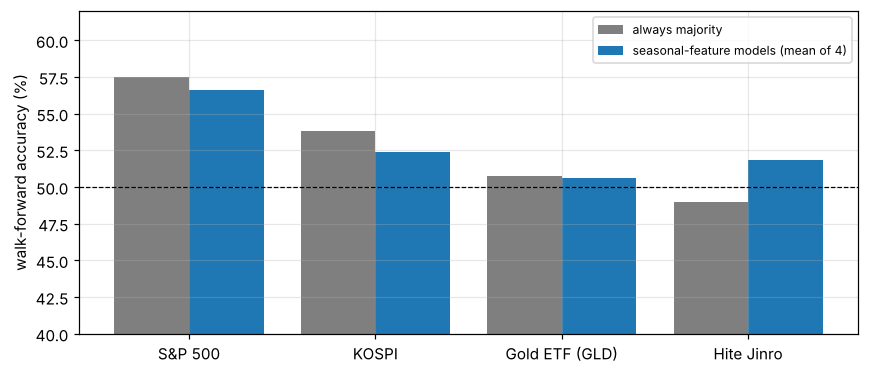

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(ASSETS))
ax.bar(x - 0.2, summary.loc["항상 다수 쪽", list(ASSETS)] * 100, width=0.4, color="tab:gray", label="always majority")
ax.bar(x + 0.2, summary.loc["계절 특성 모델 4종 평균", list(ASSETS)] * 100, width=0.4, color="tab:blue", label="seasonal-feature models (mean of 4)")
ax.axhline(50, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [ASSETS[a] for a in ASSETS])
ax.set_ylim(40, 62)
ax.set_ylabel("walk-forward accuracy (%)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### 수익률로도 확인

정확도 대신, 모델이 "상승"이라고 한 주와 "하락"이라고 한 주의 **실제 평균 수익률**이 다른지 본다.
모델에 예측력이 있다면 "상승"이라고 한 주의 수익률이 더 높아야 한다.

In [10]:
rows = []
for a, (_, y, rets, pred) in results.items():
    for (fs, name), p in pred.items():
        up, down = rets[p == 1], rets[p == 0]
        if len(up) > 5 and len(down) > 5:
            rows.append({"asset": a, "특성": fs, "방법": name, "상승 예측 주 평균(%)": up.mean(), "하락 예측 주 평균(%)": down.mean(),
                         "p": stats.ttest_ind(up, down, equal_var=False).pvalue})
spread = pd.DataFrame(rows)
print("비교한 조합 %d개 중 차이가 유의한(p<0.05) 조합: %d개" % (len(spread), (spread["p"] < 0.05).sum()))
print("'하락'이라고 한 주가 오히려 더 오른 조합: %d개" % (spread["하락 예측 주 평균(%)"] > spread["상승 예측 주 평균(%)"]).sum())
spread[spread["특성"] == "계절"].round(3)

비교한 조합 53개 중 차이가 유의한(p<0.05) 조합: 0개
'하락'이라고 한 주가 오히려 더 오른 조합: 25개


,asset,특성,방법,상승 예측 주 평균(%),하락 예측 주 평균(%),p
1,SP500,계절,k-최근접 이웃,0.265,-0.139,0.225
2,SP500,계절,랜덤 포레스트,0.207,0.349,0.612
3,SP500,계절,그레이디언트 부스팅,0.247,-0.048,0.470
13,KOSPI,계절,로지스틱 회귀,0.155,0.481,0.354
14,KOSPI,계절,k-최근접 이웃,0.186,0.146,0.889
15,KOSPI,계절,랜덤 포레스트,0.192,0.141,0.852
16,KOSPI,계절,그레이디언트 부스팅,0.248,-0.029,0.299
27,GOLD,계절,로지스틱 회귀,0.167,0.294,0.505
28,GOLD,계절,k-최근접 이웃,0.214,0.146,0.695
29,GOLD,계절,랜덤 포레스트,0.158,0.240,0.646


## 정리

- 주차별로 집계하면 그럴듯한 주차가 보인다. 하지만 52개를 한꺼번에 보면 우연히 유의한 주차가 2~3개는 나온다.
- 주차 통계를 특성으로 넣어 다음 해를 예측하면, 어떤 모델도 "항상 다수 쪽으로 찍기"를 뚜렷이 이기지 못했다.
- 모델이 "상승"이라고 한 주와 "하락"이라고 한 주의 실제 수익률 차이도 유의하지 않았다.

**왜 그런가**
- 주차당 표본이 20개 안팎이다. 한 해만 달라져도 상승 비율이 5%p씩 움직인다.
- 맥주가 여름에 잘 팔리는 것처럼 누구나 아는 계절성은 주가에 미리 반영된다. 매출의 계절성과 주가의 계절성은 다르다.

**수업 내용과의 연결**
- 과거 데이터를 잘 설명하는 것(훈련 성능)과 새 데이터를 맞히는 것(테스트 성능)은 다르다. 과대적합의 사례다.
- 시계열은 시간 순서대로 나눠 평가해야 하고, 기준선과 비교해야 모델의 가치를 알 수 있다.

방향 대신 **변동성의 크기**는 예측할 수 있었고(`volatility_forecast.ipynb`),
**움직임의 닮음**으로 ETF를 묶는 것은 잘 됐다(`etf_map.ipynb`).